# Imports

In [719]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from statsmodels.stats.outliers_influence import variance_inflation_factor
import joblib

from sklearn.feature_selection import mutual_info_classif
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, RocCurveDisplay, ConfusionMatrixDisplay, precision_recall_curve, roc_curve
from sklearn.tree import DecisionTreeClassifier
from category_encoders import TargetEncoder
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

# EDA

### primary analysis

In [616]:
df = pd.read_csv('train_df.csv', sep='\t')
df.head()

,Unnamed: 0,num_1,num_2,num_3,num_4,num_5,num_6,num_7,cat_1,num_8,...,num_413,cat_132,cat_133,num_414,num_415,num_416,cat_134,cat_135,id,gb
0,0,1377.3,3712.9,NaN,1303.0,2409.0,1281.7,43.0,1,195.0,...,11327.5,1,1,28162496.65,0.0,0.07,1,1,1,0
1,1,20.0,13.4,NaN,565.0,NaN,357.2,19.0,1,170.0,...,168.6,1,1,989383.82,0.0,0.56,2,1,2,0
2,4,150.6,1.8,NaN,2294.0,15.0,107.6,76.0,1,196.0,...,209.1,1,1,87444.51,0.0,0.01,3,1,3,0
3,5,11.4,178.0,NaN,1236.0,NaN,350.6,41.0,1,117.0,...,56.9,1,1,297608.00,0.0,0.08,4,1,4,0
4,6,5372.0,3386.0,NaN,1340.0,NaN,14.0,45.0,1,9.0,...,31.0,1,1,6614247.89,0.0,0.20,1,1,5,0


In [617]:
print(df.shape)
print(df.info())

(26824, 554)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26824 entries, 0 to 26823
Columns: 554 entries, Unnamed: 0 to gb
dtypes: float64(416), int64(138)
memory usage: 113.4 MB
None


### visual analysis

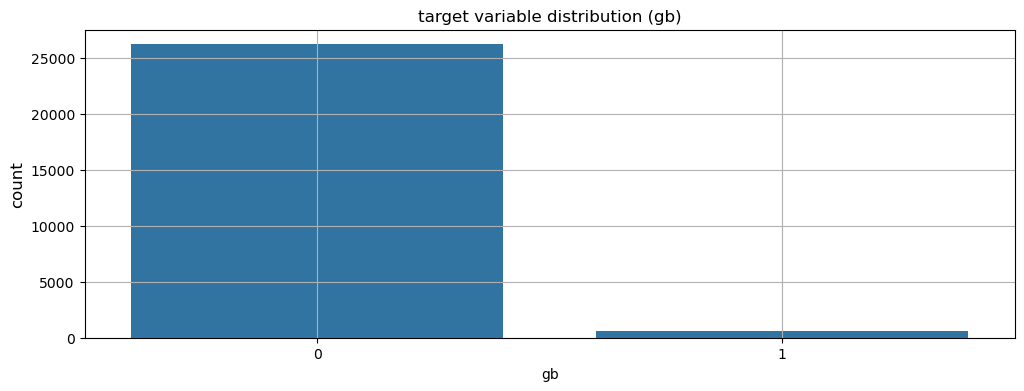

In [619]:
plt.figure(figsize=(12, 4))
sns.countplot(x='gb', data=df)
plt.title('target variable distribution (gb)')
plt.xlabel('gb')
plt.ylabel('count', fontsize=12)
plt.grid(True)
plt.show()

З розподілу бачимо сильний дисбаланс класів. Потрібно буде використати балансування, щоб не було частого випадкового прогнозування "0".

Також, використоуватимемо ROC-AUC, F1-score або Precision-Recall замість Accuracy (не враховує кількості, тому ігнорує помилки в меншому класі).


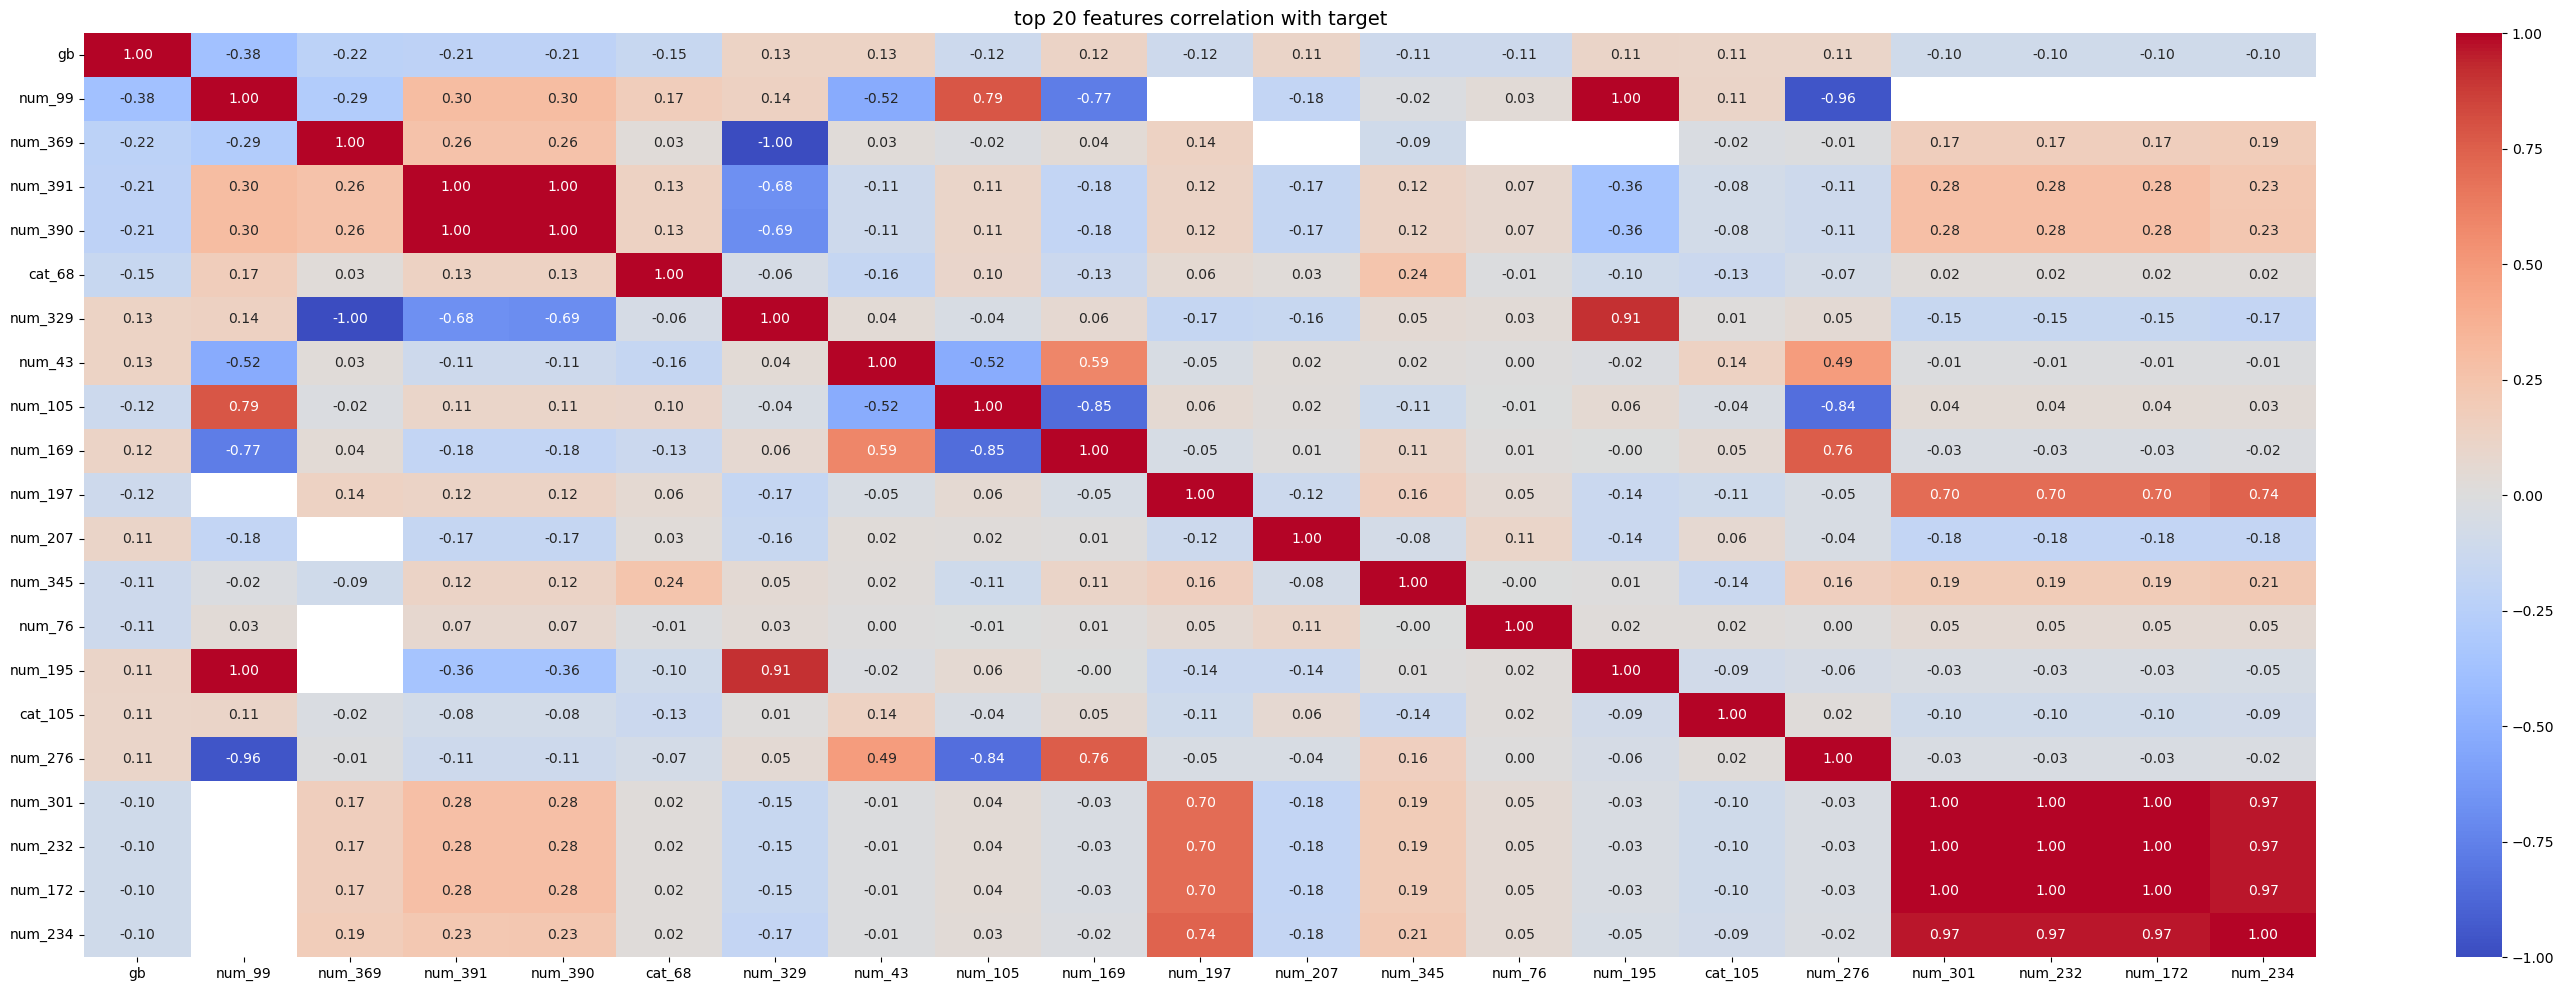

In [620]:
plt.figure(figsize=(36, 12))
top_corr_features = df.corr()['gb'].abs().sort_values(ascending=False).head(21).index
sns.heatmap(df[top_corr_features].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('top 20 features correlation with target', fontsize=14)
plt.show()

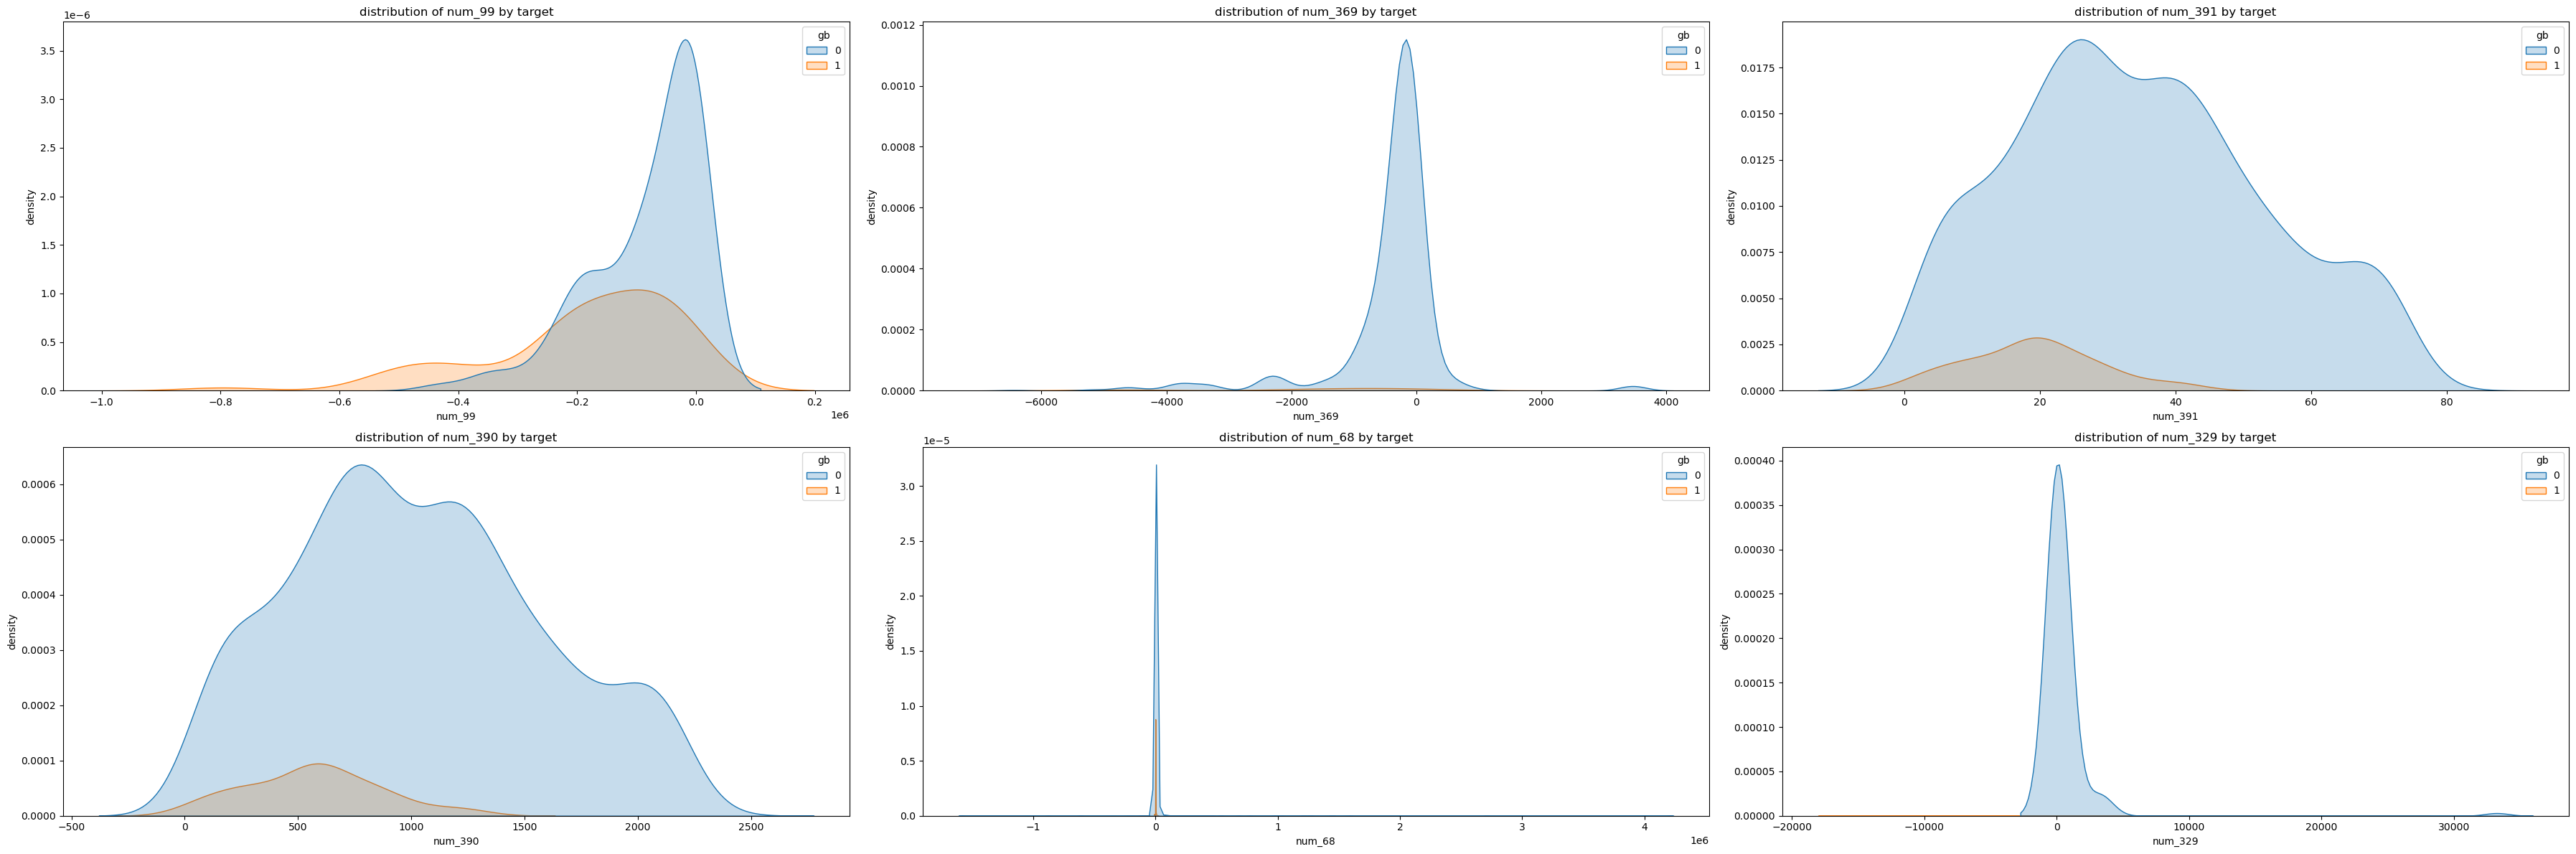

In [621]:
features_to_plot = ['num_99', 'num_369', 'num_391', 'num_390', 'num_68', 'num_329']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(36, 12))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    sns.kdeplot(data=df, x=col, hue='gb', fill=True, ax=axes[i])
    axes[i].set_title(f'distribution of {col.lower()} by target', fontsize=12)
    axes[i].set_xlabel(col.lower(), fontsize=10)
    axes[i].set_ylabel('density', fontsize=10)

plt.tight_layout()
plt.show()

Визначаємо 20 стовпців із найбільшою кореляцією з gb. Навіть найкраща кореляція не висока (від 0.11 до 0.38 для 16 стовпців, та <= 0.1 для інших).

Для топ-6 візуалізовуємо розподіл класів за значеннями. Графіки майже накладаються, ознаки погано самостійно розрізнятимуть класи.

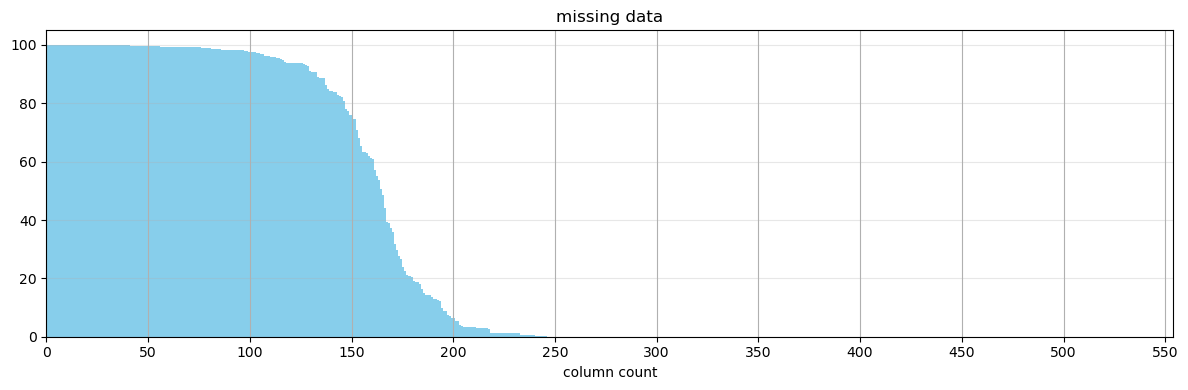

In [622]:
missing = df.isnull().mean().sort_values(ascending=False) * 100

plt.figure(figsize=(12, 4))
plt.bar(range(len(missing)), missing.values, color='skyblue', width=1, align='edge')

plt.title('missing data')
plt.xlabel('column count')

plt.xlim(0, len(missing))
plt.xticks(np.arange(0, 555, 50))
plt.gca().yaxis.grid(True, linestyle='-', alpha=0.3)
plt.gca().xaxis.grid(False)

plt.tight_layout()
plt.grid(True)
plt.show()

В стовпцях датасету, з огляду, багато пропущених даних. Детальніше проаналізуємо це наступного кроку.

### columns (missing data)

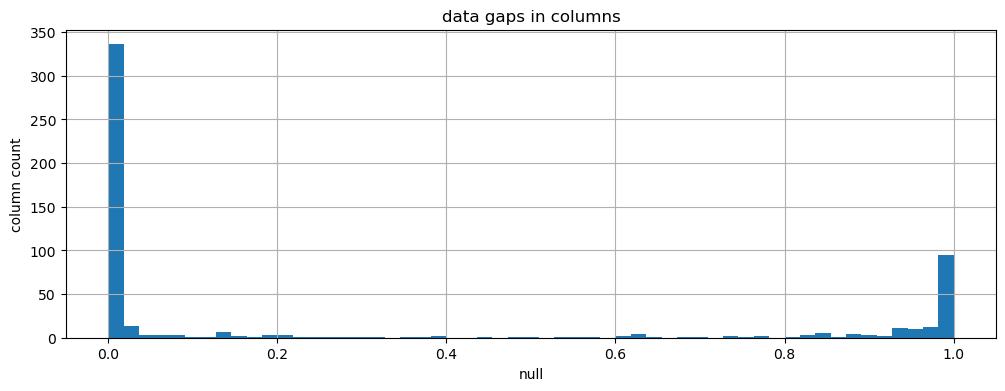

In [623]:
plt.figure(figsize=(12, 4))
null_counts = df.isnull().mean()

null_counts.plot(kind='hist', bins=55, title='data gaps in columns')
plt.xlabel('null')
plt.ylabel('column count')
plt.grid(True)
plt.show()

Зобразимо гістограму пропущених значень в стовпцях. В частині дані практично відсутні, в іншій частині - практично всі дані є.

Близько ста стовпців з кількістю пропусків, близькою до 1. Це значна частина даних, тому необхідно детальніше дослідити пропуски.

In [624]:
empty_columns = null_counts[null_counts == 1.0].index.tolist()

print(f"quantity: {len(empty_columns)}")
print(empty_columns)

quantity: 12
['num_23', 'num_66', 'num_150', 'num_152', 'num_242', 'num_250', 'num_258', 'num_266', 'num_342', 'num_365', 'num_375', 'num_392']


In [625]:
df.drop(columns = empty_columns, inplace=True)

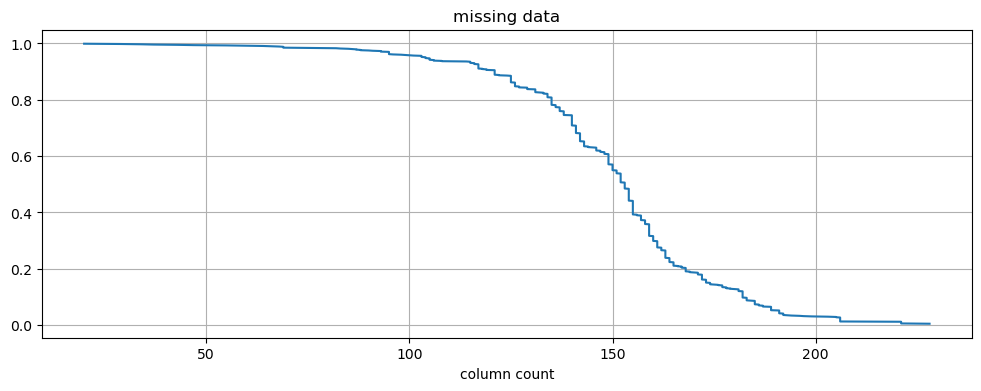

In [626]:
non_null = df.isnull().mean()

x_values = np.arange(0.005, 1, 0.001)
y_values = [non_null[non_null >= x].shape[0] for x in x_values]

plt.figure(figsize=(12, 4))
plt.plot(y_values, x_values, marker='') 

plt.title('missing data')
plt.xlabel('column count') 
plt.grid(True)
plt.show()

In [627]:
null_counts = df.isnull().mean()
cols_to_drop = null_counts[null_counts > 0.6].index.tolist() # тобто, data < 0.4

df.drop(columns=cols_to_drop, inplace=True)

print(f"quantity: {len(cols_to_drop)}")
print(cols_to_drop)

quantity: 149
['num_3', 'num_11', 'num_12', 'num_17', 'num_18', 'num_20', 'num_21', 'num_22', 'num_24', 'num_25', 'num_31', 'num_34', 'num_35', 'num_36', 'num_37', 'num_39', 'num_42', 'num_44', 'num_46', 'num_47', 'num_48', 'num_49', 'num_51', 'num_56', 'num_61', 'num_63', 'num_65', 'num_73', 'num_76', 'num_78', 'num_82', 'num_86', 'num_89', 'num_90', 'num_91', 'num_93', 'num_96', 'num_98', 'num_99', 'num_100', 'num_101', 'num_103', 'num_106', 'num_108', 'num_109', 'num_116', 'num_118', 'num_121', 'num_125', 'num_126', 'num_127', 'num_131', 'num_135', 'num_138', 'num_140', 'num_142', 'num_143', 'num_146', 'num_149', 'num_153', 'num_156', 'num_157', 'num_160', 'num_163', 'num_166', 'num_170', 'num_171', 'num_182', 'num_189', 'num_190', 'num_192', 'num_195', 'num_198', 'num_199', 'num_204', 'num_207', 'num_208', 'num_210', 'num_215', 'num_217', 'num_221', 'num_222', 'num_223', 'num_224', 'num_226', 'num_227', 'num_229', 'num_236', 'num_241', 'num_243', 'num_245', 'num_247', 'num_248', 'n

Робота з пропусками.

- 12 стовпців повністю порожні - видаляємо їх.

Зобразимо графік 'missing data' щоб візуально краще оцінити кількості пропусків (частина графіка з visual analysis) Бачимо, що багато даних з > 0.6 пропусків (тобто, є всього < 0.4 даних). Високий ризик перенавчання. Модель не зможе вивчити патерн, який зустрічається у 0.005 даних

- також видаляємо 149 стовпців, в яких < 0.4 даних присутні.

### rows

` duplicates `

In [618]:
duplicates_all = df.duplicated().sum()
print(f"complete duplicates: {duplicates_all}")

complete duplicates: 0


In [628]:
duplicates_id = df.duplicated(subset=['id']).sum()
print(f"by column 'id': {duplicates_id}")

by column 'id': 21581


In [629]:
cols_to_check = df.columns.difference(['id', 'Unnamed: 0'])
duplicates_data = df.duplicated(subset=cols_to_check).sum()
print(f"duplicates by content (without id): {duplicates_data}")

duplicates by content (without id): 0


In [630]:
sample_id = df[df.duplicated(subset=['id'])]['id'].iloc[0]
df[df['id'] == sample_id].head()

,Unnamed: 0,num_1,num_2,num_4,num_5,num_6,num_7,cat_1,num_8,num_9,...,num_413,cat_132,cat_133,num_414,num_415,num_416,cat_134,cat_135,id,gb
1372,2716,3485.3,1126.5,2171.0,61.5,1742.5,72.0,1,170.0,0.7,...,6587.5,1,2,2747823.80,76.66,0.01,3,1,1373,0
1464,2920,3485.3,1126.5,2202.0,61.5,1742.5,73.0,1,201.0,0.7,...,6587.5,1,2,3188225.80,76.66,0.01,3,1,1373,0
5376,11136,3485.3,1126.5,2233.0,61.5,1742.5,74.0,1,232.0,0.7,...,6587.5,1,2,3066225.80,76.66,0.01,3,1,1373,0
9080,19302,3485.3,1126.5,2263.0,61.5,1742.5,75.0,1,10.0,0.7,...,6587.5,1,2,4781225.12,76.66,0.01,3,1,1373,0
9682,20663,3485.3,1126.5,2294.0,61.5,1742.5,76.0,1,41.0,0.7,...,6587.5,1,2,6973436.42,76.66,0.02,3,1,1373,0


Повних дублікатів в нас немає, але, є 21581 дублікат за "id". Якщо тренувати модель на цих даних, перетренуємо один і той самий об'єкт/людину з різними ознаками.

In [631]:
check_gb = df.groupby('id')['gb'].nunique()
inconsistent_ids_list = check_gb[check_gb > 1].index.tolist()
rows_to_drop_inconsistent = df[df['id'].isin(inconsistent_ids_list)].index.tolist()

In [632]:
print(f"quantity: {len(rows_to_drop_inconsistent)}")
print(rows_to_drop_inconsistent)

quantity: 68
[36, 301, 345, 363, 374, 438, 1101, 1133, 1354, 2018, 2239, 2255, 2703, 3016, 3209, 3491, 3682, 3809, 3894, 5379, 5553, 5609, 5635, 5995, 6010, 6437, 6845, 7437, 7783, 7829, 7953, 8949, 9919, 10144, 10188, 11554, 11771, 13208, 14250, 14329, 14816, 15076, 16249, 16911, 17839, 17929, 19126, 19411, 20186, 20260, 20366, 20432, 20845, 20875, 21286, 21878, 21938, 22458, 23250, 23561, 23873, 25017, 25548, 25961, 25977, 26143, 26673, 26732]


In [633]:
df = df.drop(index=rows_to_drop_inconsistent)
df = df.reset_index(drop=True)

Перевіримо 'gb' для одного 'id'. Вона незмінна в переважній більшості випадків.
Для 68 рядків з 5243 випадків, приблизно, 13 об'єктів/людей, 'gb' змінюється (< 0.0025). Вважатимемо це помилкою та позбудемося цих рядків.

Скоріше за все це проблема вивантаження чи склеювання даних. Але навіть якщо це прогноз де клієнт спочатку був '1', а через якийсь час став '0', це лише зашкодить моделі, обидва статуси для одного id з, відповідно, схожими ознаками клієнта - шум.

` aggregation `

In [634]:
unique_counts = df.groupby('id').nunique()

dynamic_cols = unique_counts.columns[(unique_counts > 1).any()].tolist()
static_cols = unique_counts.columns[(unique_counts <= 1).all()].tolist()

print(f"dynamic (temporal): {len(dynamic_cols)}")
print(f"static (constants): {len(static_cols)}")
print(f"static :{static_cols}")

dynamic (temporal): 391
static (constants): 1
static :['gb']


In [635]:
num_cols = [c for c in df.columns if c.startswith('num_')]
cat_cols = [c for c in df.columns if c.startswith('cat_')]

In [636]:
agg_func = {col: ['mean', 'std'] for col in num_cols}
for col in cat_cols:
    agg_func[col] = ['nunique', 'last']

agg_func['gb'] = 'last'

df = df.groupby('id').agg(agg_func)
df.columns = ['_'.join(col).strip() for col in df.columns.values]

In [637]:
df['row_count'] = unique_counts.iloc[:, 0]
df = df.rename(columns={'gb_last': 'gb'})

df = df.loc[:, df.nunique() > 1]
df = df.copy()

print(df.shape)

(5230, 782)


/var/folders/lc/txlwmxx91wz8fm_fqvv9b4v80000gn/T/ipykernel_14407/1601089824.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['row_count'] = unique_counts.iloc[:, 0]


In [638]:
duplicates_id = df.reset_index().duplicated(subset=['id']).sum()
print(f"by column 'id': {duplicates_id}")

by column 'id': 0


Далі виконаємо агрегацію рядків. Зіллємо рядки з однаковим 'id' в один.

Всі рядки, окрім цільової змінної, є динамічними. Тому оберемо таку стратегію злиття:

- для числових даних створюємо середнє та стандартне відхилення (матемемо інформацію про те, яке значення в нас всередньому було, та як воно змінювалося)
- для категоріальних - nunique (кількість унікальних значень) та останній, актуальний стан.

# Preprocessing

### train-test split

In [639]:
X = df.drop(columns=['gb'])
y = df['gb']

In [640]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,
    random_state=42,
    stratify=y
)

### columns (redundancy removal)

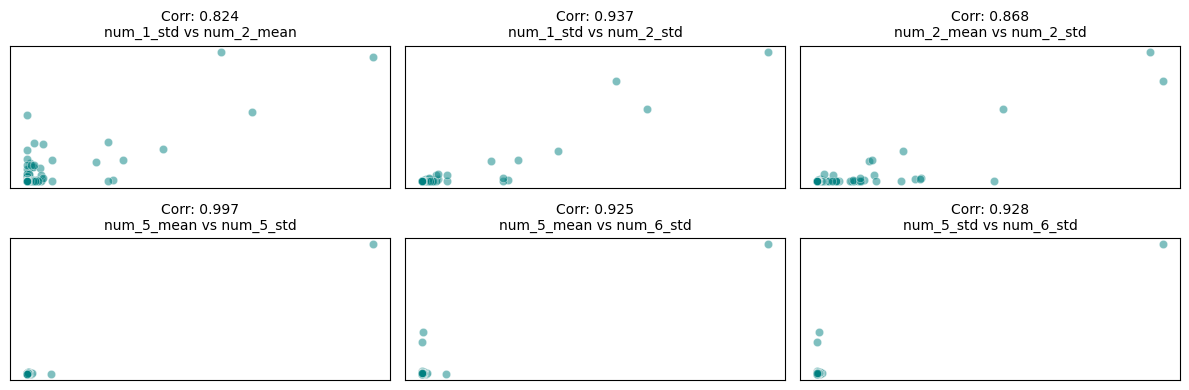

In [641]:
corr_matrix = X_train.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [(r, c, upper.loc[r, c]) for c in upper.columns for r in upper.index if upper.loc[r, c] > 0.8]

fig, axes = plt.subplots(2, 3, figsize=(12, 4))
axes = axes.flatten()

for i in range(min(6, len(high_corr_pairs))):
    f1, f2, val = high_corr_pairs[i]
    sns.scatterplot(x=X_train[f1], y=X_train[f2], ax=axes[i], alpha=0.5, color='teal')
    
    axes[i].set_title(f"Corr: {val:.3f}\n{f1} vs {f2}", fontsize=10)
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].set(xlabel=None, ylabel=None, xticks=[], yticks=[])

for j in range(i + 1, 6):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

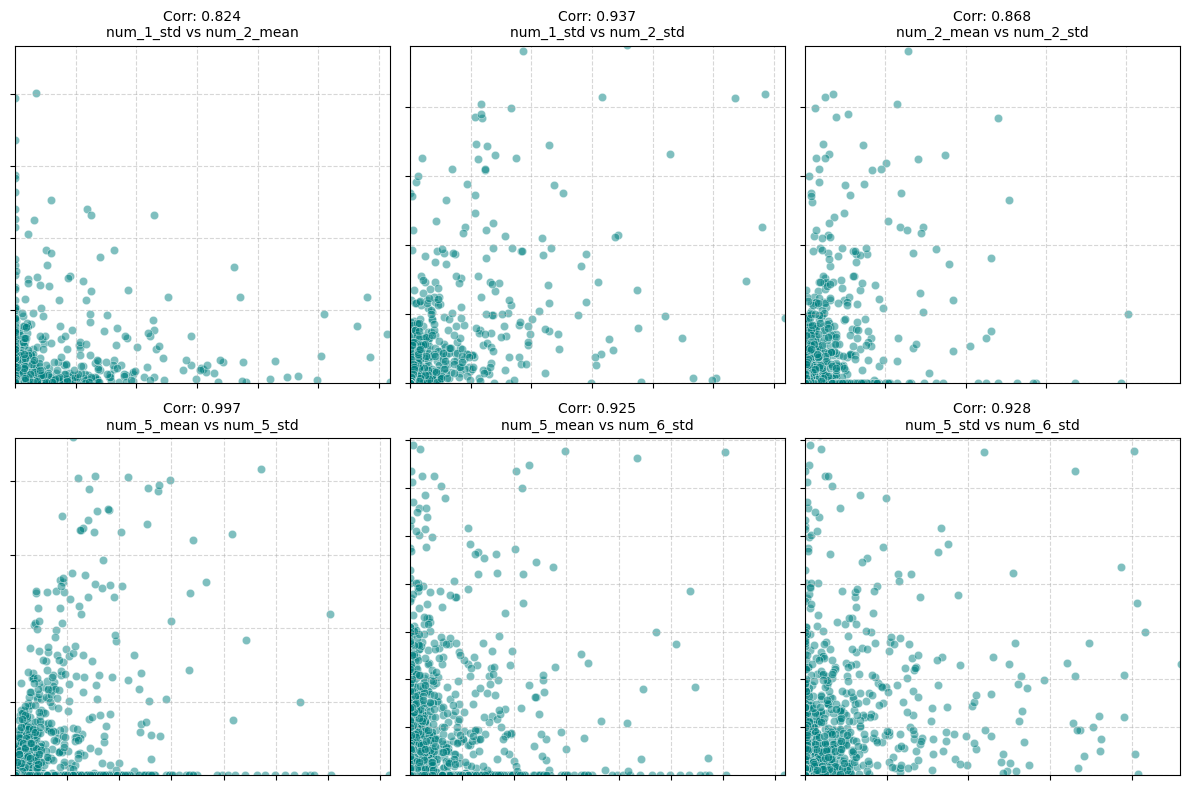

In [642]:
corr_matrix = X_train.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [(r, c, upper.loc[r, c]) for c in upper.columns for r in upper.index if upper.loc[r, c] > 0.8]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for i in range(min(6, len(high_corr_pairs))):
    f1, f2, val = high_corr_pairs[i]
    
    x_limit = X_train[f1].quantile(0.99)
    y_limit = X_train[f2].quantile(0.99)
    
    sns.scatterplot(x=X_train[f1], y=X_train[f2], ax=axes[i], alpha=0.5, color='teal')
    
    axes[i].set_xlim(X_train[f1].min(), x_limit)
    axes[i].set_ylim(X_train[f2].min(), y_limit)
    axes[i].set_title(f"Corr: {val:.3f}\n{f1} vs {f2}", fontsize=10)
    axes[i].grid(True, linestyle='--', alpha=0.5)
    
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')
    axes[i].tick_params(axis='both', which='both', labelbottom=False, labelleft=False)

for j in range(i + 1, 6):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Зобразимо графік кореляції для 6 пар з найбільшою кореляцією. Для наочності, зобразимо їх ще раз, обмеживши осі графіків, щоб не відображати екстримальні значення.

Спостерігаємо дуже високу кореляцію.

Тож, далі дослідимо кореляцію та мультокореляцію між стовпцями.

` collinearity (correlation > 0.8) ` 

In [643]:
X_train_num = X_train[[col for col in X_train.columns if col.startswith('num_')]]
print(X_train_num.shape)

(4184, 510)


In [644]:
corr_matrix = X_train_num.corr().abs()
mean_corr = corr_matrix.mean()
null_counts = X_train_num.isnull().sum()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

pairs = np.where(upper > 0.8)
high_corr_pairs = [(upper.index[i], upper.columns[j]) for i, j in zip(*pairs)]

to_drop_corr = set()
for col1, col2 in high_corr_pairs:
    if col1 in to_drop_corr or col2 in to_drop_corr:
        continue
        
    if null_counts[col1] > null_counts[col2]:
        to_drop_corr.add(col1)
    elif null_counts[col2] > null_counts[col1]:
        to_drop_corr.add(col2)
    else:
        if mean_corr[col1] > mean_corr[col2]:
            to_drop_corr.add(col1)
        else:
            to_drop_corr.add(col2)

to_drop_corr = list(to_drop_corr)

print(f"quantity: {len(to_drop_corr)}")
print(to_drop_corr)

quantity: 284
['num_71_mean', 'num_154_mean', 'num_398_std', 'num_113_mean', 'num_13_std', 'num_33_mean', 'num_175_mean', 'num_83_std', 'num_214_std', 'num_389_std', 'num_1_mean', 'num_381_mean', 'num_321_std', 'num_381_std', 'num_238_std', 'num_332_mean', 'num_148_mean', 'num_177_mean', 'num_113_std', 'num_303_mean', 'num_283_std', 'num_10_mean', 'num_6_std', 'num_5_mean', 'num_309_std', 'num_378_std', 'num_389_mean', 'num_120_std', 'num_319_std', 'num_413_mean', 'num_409_mean', 'num_181_mean', 'num_81_std', 'num_268_std', 'num_303_std', 'num_312_std', 'num_137_mean', 'num_174_std', 'num_79_std', 'num_262_std', 'num_239_mean', 'num_88_std', 'num_396_std', 'num_407_std', 'num_94_mean', 'num_398_mean', 'num_97_std', 'num_270_mean', 'num_13_mean', 'num_379_std', 'num_405_mean', 'num_404_mean', 'num_410_mean', 'num_292_mean', 'num_289_mean', 'num_406_std', 'num_196_std', 'num_28_mean', 'num_228_mean', 'num_154_std', 'num_340_std', 'num_54_mean', 'num_176_std', 'num_38_mean', 'num_173_std'

In [645]:
X_train = X_train.drop(columns=[col for col in to_drop_corr if col in X_train.columns])

По одному елементу з кожної пари, в яких висока кореляція, ми видалятимемо щоб уникнути випадкової ваги для ознак.

Встановимо межу 0.8, якщо між стовпцями кореляція на такому рівні чи вища - видаляємо один із них (а саме, той, у якому більше пустих значень, якщо порівну - той який у середньому сильніше корелює з усіма іншими числовими ознаками).

In [ ]:
num_cols = [col for col in X_train.columns if col.startswith("num_")]
X = X_train[num_cols].copy()
X = X.fillna(X.median())
X = X.loc[:, X.nunique() > 1]

cols_to_drop_vif = []
keep_calculating = True

while keep_calculating:
    variables = X.columns
    vif = [variance_inflation_factor(X.values, i) for i in range(len(variables))]
    
    max_vif = max(vif)
    if max_vif > 10:
        max_idx = vif.index(max_vif)
        col_name = variables[max_idx]
        
        cols_to_drop_vif.append(col_name)
        X = X.drop(columns=[col_name])
    else:
        keep_calculating = False

print(f"quantity: {len(cols_to_drop_vif)}")
print(cols_to_drop_vif)

'\n\nnum_cols = [col for col in X_train.columns if col.startswith("num_")]\nX = X_train[num_cols].copy()\nX = X.fillna(X.median())\nX = X.loc[:, X.nunique() > 1]\n\ncols_to_drop_vif = []\nkeep_calculating = True\n\nwhile keep_calculating:\n    variables = X.columns\n    vif = [variance_inflation_factor(X.values, i) for i in range(len(variables))]\n    \n    max_vif = max(vif)\n    if max_vif > 10:\n        max_idx = vif.index(max_vif)\n        col_name = variables[max_idx]\n        \n        cols_to_drop_vif.append(col_name)\n        X = X.drop(columns=[col_name])\n    else:\n        keep_calculating = False\n\nprint(f"quantity: {len(cols_to_drop_vif)}")\nprint(cols_to_drop_vif)\n\n'

In [648]:
X_train = X_train.drop(columns=[col for col in cols_to_drop_vif if col in X_train.columns])

In [649]:
X_train.shape

(4184, 487)

Далі перевірили стовпці на мультиколінеарність. Стовпці з vif > 10 видалятимемо. Але щоб уникнути впливу стовпців, які вже обрали для видалення, порівнюватимемо щоразу далі вже без них. Таким чином видаляємо ще 10 стовпців.

Завершимо очищення зайвої інформації перевіркою на константність. Дані з однаковими, або майже однаковими значеннями, не є корисними для розрізняння класів.

` constancy (frequency > 0.99) `

In [650]:
most_freq_ratio = X_train.apply(lambda x: x.value_counts(normalize=True).iloc[0])
quasi_constant_cols = most_freq_ratio[most_freq_ratio >= 0.99].index.tolist()

print(f"quantity: {len(quasi_constant_cols)}")
print(quasi_constant_cols)

quantity: 112
['num_102_std', 'num_225_std', 'num_367_mean', 'cat_1_nunique', 'cat_1_last', 'cat_4_nunique', 'cat_4_last', 'cat_7_nunique', 'cat_7_last', 'cat_10_nunique', 'cat_10_last', 'cat_11_nunique', 'cat_11_last', 'cat_12_nunique', 'cat_12_last', 'cat_13_nunique', 'cat_13_last', 'cat_17_nunique', 'cat_17_last', 'cat_20_nunique', 'cat_20_last', 'cat_21_nunique', 'cat_22_nunique', 'cat_22_last', 'cat_23_nunique', 'cat_23_last', 'cat_25_nunique', 'cat_25_last', 'cat_26_nunique', 'cat_26_last', 'cat_29_nunique', 'cat_29_last', 'cat_30_nunique', 'cat_30_last', 'cat_31_nunique', 'cat_31_last', 'cat_32_nunique', 'cat_32_last', 'cat_33_nunique', 'cat_33_last', 'cat_35_nunique', 'cat_41_nunique', 'cat_41_last', 'cat_42_nunique', 'cat_42_last', 'cat_43_nunique', 'cat_44_nunique', 'cat_46_nunique', 'cat_47_nunique', 'cat_47_last', 'cat_48_nunique', 'cat_49_nunique', 'cat_51_nunique', 'cat_51_last', 'cat_53_nunique', 'cat_53_last', 'cat_55_nunique', 'cat_55_last', 'cat_56_nunique', 'cat_56_l

In [651]:
important_quasi = []

for col in quasi_constant_cols:
    check = y_train.groupby(X_train[col]).mean()
    
    if check.max() > 0.5:
        important_quasi.append(col)

important_quasi

['num_225_std']

In [652]:
X_train = X_train.drop(columns=[col for col in quasi_constant_cols if col in X_train.columns and col != 'num_225_std'])

Стовпців, які мають константні дані, або > 0.99 однакових даних, виявилося 112. Також ці дані не збігаються з рідкісним класом у gb, окрім 'num_225_std'.

Тож, видаляємо 111 зі 112, окрім одного винятка, оскільки такі дані несуть мало корисної інформації, натомість можуть створити зайвий шум.

### imputation

Оскільки, в деяких стовпцях, як зазначали раніше, інформація присутня майже повністю, а в інших, майже повністю відсутня, спробуємо метод роботи з пропусками, щоб мінімалізувати спотворення даних.

А саме, використаємо IterativeImputer, щоб розглянути кожен стовпець з пропусками як цільову змінну, а інші стовпці — як прогнози. Оскільки, в багатьох з інших рядків буде дуже багато даних, вони можуть добре допомогти спрогнозувати потрібний. А також, регресійна модель для передбачення пропущених значень дозволить зберегти зв'язки та статистичні закономірності між ознаками.

In [653]:
num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns

it_imputer = IterativeImputer(max_iter=10, initial_strategy='median', random_state=42)
X_train[num_cols] = it_imputer.fit_transform(X_train[num_cols])

In [654]:
print(f"gaps after imputation: {X_train[num_cols].isnull().sum().sum()}")

gaps after imputation: 0


In [655]:
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns
X_train[cat_cols] = X_train[cat_cols].fillna('Unknown')

In [656]:
print(f"total nan: {X_train.isna().sum().sum()}")

total nan: 0


In [657]:
X_train.isna().sum().sum()

np.int64(0)

- заповнили пропущені числові дані з допомогою IterativeImputer.
- для категоріальних створили окрему категорію "Unknown". Це дозволить моделі врахувати факт відсутності даних як окрему ознаку.

### categorical feature encoding

In [658]:
X_train.filter(like='cat_').nunique()

cat_2_nunique      2
cat_2_last         3
cat_3_nunique      2
cat_3_last         3
cat_5_nunique      2
                  ..
cat_132_nunique    2
cat_132_last       3
cat_133_last       2
cat_134_nunique    2
cat_134_last       8
Length: 161, dtype: int64

In [659]:
def encode_categorical_last_states(X, y=None, threshold=10):
    X = X.copy()
    cat_last_cols = [col for col in X.columns if col.startswith('cat_') and col.endswith('_last')]
    
    cols_to_target = [col for col in cat_last_cols if X[col].nunique() > threshold]
    cols_to_dummy = [col for col in cat_last_cols if X[col].nunique() <= threshold]
    
    encoder = None
    if cols_to_target and y is not None:
        encoder = TargetEncoder(cols=cols_to_target)
        X = encoder.fit_transform(X, y)
    
    if cols_to_dummy:
        X = pd.get_dummies(X, columns=cols_to_dummy, drop_first=True, dtype=int)
                
    return X, encoder

In [660]:
X_train_enc, trained_encoder = encode_categorical_last_states(X_train, y=y_train, threshold=10)
X_train_enc.shape

(4184, 512)

До категоріальних стовпців (cat_..._last - які залишилися категоріями) застосували два способи обробки:

- One-hot encoding для стовпців, в яких < 10 значень.
- Target Encoding якщо в стовпці > 10 значень.

Маємо повністю числовий датасет (де кожну категорілальну представили бінарним стовпцем, або статистичною вагою, відповідно).

` Feature Selection MI `

In [661]:
X_temp = X_train_enc.fillna(0)
y_temp = y_train

mi_scores = mutual_info_classif(X_temp, y_temp, random_state=42)
mi_series = pd.Series(mi_scores, index=X_temp.columns)

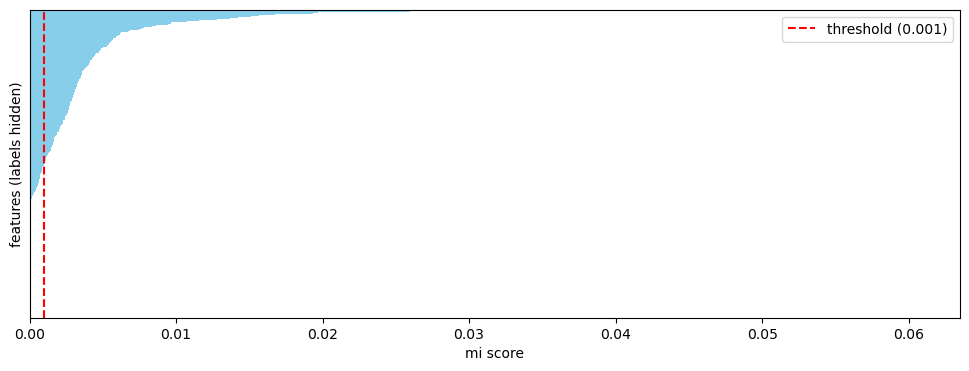

In [662]:
top_mi = mi_series.sort_values(ascending=False)

top_mi.plot(kind='barh', color='skyblue', width=1.0, figsize=(12, 4))
plt.axvline(x=0.001, color='red', linestyle='--', label='threshold (0.001)')

plt.xlabel('mi score')
plt.ylabel('features (labels hidden)')
plt.yticks([])
plt.gca().invert_yaxis()
plt.legend()
plt.savefig('mi_scores.png')

In [663]:
selected_features = mi_series[mi_series > 0.001].index.tolist()
X_train_enc = X_train_enc[selected_features]

print(f"number of features: {len(selected_features)}")

number of features: 256


In [664]:
X_train_enc.shape

(4184, 256)

Додатково, оцінимо графік кореляції стовпців, які зараз в датасеті з 'gb'.

Залишаємо ознаки, що мають достатній статистичний зв’язок із цільовою змінною gb, відсіявши інформаційний шум.

### feature scaling

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_enc)

X_train = pd.DataFrame(X_train_scaled, columns=selected_features)

In [666]:
print(f"mean: {X_train.mean().mean():.2f}, std: {X_train.std().mean():.2f}")

mean: 0.00, std: 1.00


Ввикористали StandardScaler для стандартизації ознак. Звели їх до єдиного масштабу із середнім значенням 0 та стандартним відхиленням 1.

Це потрібно, щоб алгоритми не надавали надмірної ваги змінним із більшими числовими діапазонами.

### pipeline state

In [667]:
joblib.dump(it_imputer, 'it_imputer.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(trained_encoder, 'target_encoder.pkl')
joblib.dump(selected_features, 'selected_features.pkl')

['selected_features.pkl']

Збережемо навчені об'єкти препроцесингу та список відібраних ознак у файли. Щоб застосувати до нових вхідних даних точно такі самі параметри трансформації, які використовувалися під час навчання.

# Data Structuring / Reshaping

Додамо функції, transform_test_set для перетворення тестового набору у формат, в якому тренуватимемо дані. Та prepare_raw_data, для обробки повного набору даних, з яким на робили взагалі ніяких змін, в потрібний формат.

In [668]:
def prepare_raw_data(df_input):
    df = df_input.copy()
    
    to_drop_initial = list(set(empty_columns + cols_to_drop))
    df = df.drop(columns=[c for c in to_drop_initial if c in df.columns], errors='ignore')

    num_cols_raw = [c for c in df.columns if c.startswith('num_')]
    cat_cols_raw = [c for c in df.columns if c.startswith('cat_')]
    
    agg_dict = {col: ['mean', 'std'] for col in num_cols_raw}
    for col in cat_cols_raw:
        agg_dict[col] = ['nunique', 'last']
    
    if 'gb' in df.columns:
        agg_dict['gb'] = 'last'

    df_agg = df.groupby('id').agg(agg_dict)
    df_agg.columns = ['_'.join(col).strip() for col in df_agg.columns.values]
    df_agg['row_count'] = df.groupby('id').size()
    
    return df_agg

In [669]:
def transform_test_set(X_test_agg, imputer, scaler, encoder, final_features):
    X = X_test_agg.copy()

    cols_to_remove = list(set(to_drop_corr + cols_to_drop_vif + 
                              [c for c in quasi_constant_cols if c != 'num_225_std']))
    X = X.drop(columns=[c for c in cols_to_remove if c in X.columns], errors='ignore')

    num_cols_current = X.select_dtypes(include=['float64', 'int64']).columns
    X[num_cols_current] = imputer.transform(X[num_cols_current])

    cat_cols = X.select_dtypes(include=['object', 'category']).columns
    X[cat_cols] = X[cat_cols].fillna('Unknown')

    if encoder is not None:
        X = encoder.transform(X)

    X = pd.get_dummies(X, drop_first=True, dtype=int)

    for col in final_features:
        if col not in X.columns:
            X[col] = 0
            
    X = X[final_features]

    X_scaled = scaler.transform(X)
    
    return pd.DataFrame(X_scaled, columns=final_features, index=X.index)

In [670]:
X_train

,num_2_mean,num_4_mean,num_7_std,num_8_mean,num_8_std,num_15_mean,num_16_std,num_26_std,num_27_mean,num_29_mean,...,cat_112_last_2.0,cat_113_last_3.0,cat_117_last_2.0,cat_119_last_3.0,cat_120_last_2.0,cat_121_last_2.0,cat_126_last_2.0,cat_131_last_2.0,cat_131_last_4.0,cat_132_last_2.0
0,-0.049406,1.214078,-0.892175,-0.993261,-0.863846,0.369467,-0.005656,1.732053,-0.005653,-0.063724,...,-0.138726,-0.239513,-0.240071,-0.015462,-2.742514,-1.373866,-0.030934,-0.206426,-0.015462,-0.101902
1,-0.080252,-0.484376,-0.258986,-0.559854,-0.447978,0.369467,-0.027135,-0.212549,-0.004051,-0.155214,...,-0.138726,-0.239513,4.165438,-0.015462,0.364629,0.727873,-0.030934,-0.206426,-0.015462,-0.101902
2,-0.030637,1.341330,0.019692,0.783953,-0.038250,0.721811,-0.027137,4.855684,-0.000081,-0.391027,...,-0.138726,-0.239513,-0.240071,-0.015462,0.364629,-1.373866,-0.030934,-0.206426,-0.015462,-0.101902
3,-0.063578,0.655060,-1.099794,-1.012632,-1.243220,-0.159049,-0.027141,-0.636720,0.003444,-0.429869,...,-0.138726,-0.239513,-0.240071,-0.015462,0.364629,0.727873,-0.030934,-0.206426,-0.015462,-0.101902
4,2.839726,-0.568703,-1.508214,0.953443,0.598953,-0.159049,0.092087,-0.235517,12.853489,-0.383129,...,-0.138726,4.175131,-0.240071,-0.015462,-2.742514,0.727873,-0.030934,-0.206426,-0.015462,-0.101902
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4179,-0.062660,0.370983,0.298109,0.835838,1.498472,-0.159049,-0.027139,-0.422672,-0.011213,0.344923,...,-0.138726,-0.239513,-0.240071,-0.015462,0.364629,-1.373866,-0.030934,-0.206426,-0.015462,-0.101902
4180,-0.063551,0.791878,0.854490,-0.625228,-0.067885,1.426499,-0.027136,-0.268852,0.004795,-0.425479,...,-0.138726,-0.239513,-0.240071,-0.015462,0.364629,0.727873,-0.030934,-0.206426,-0.015462,-0.101902
4181,-0.056120,1.441991,-0.928970,-1.128853,-1.101499,-0.159049,-0.005928,-0.357325,-0.000020,-0.197272,...,7.208469,-0.239513,-0.240071,-0.015462,0.364629,-1.373866,-0.030934,4.844361,-0.015462,-0.101902
4182,-0.058974,-1.375577,-0.538101,-0.424262,-0.024838,-0.159049,-0.027141,-0.037247,0.019094,-0.408871,...,-0.138726,-0.239513,-0.240071,-0.015462,0.364629,-1.373866,-0.030934,-0.206426,-0.015462,-0.101902


In [671]:
X_test = transform_test_set(X_test, it_imputer, scaler, trained_encoder, selected_features)
X_test

,num_2_mean,num_4_mean,num_7_std,num_8_mean,num_8_std,num_15_mean,num_16_std,num_26_std,num_27_mean,num_29_mean,...,cat_112_last_2.0,cat_113_last_3.0,cat_117_last_2.0,cat_119_last_3.0,cat_120_last_2.0,cat_121_last_2.0,cat_126_last_2.0,cat_131_last_2.0,cat_131_last_4.0,cat_132_last_2.0
id,,,,,,,,,,,,,,,,,,,,,
1207,-0.063318,0.446773,-0.871099,-0.431526,-0.875710,-0.159049,-0.005523,-0.098863,-0.074940,-0.400065,...,-0.138726,-0.239513,-0.240071,-0.015462,-2.742514,-1.373866,-0.030934,-0.206426,-0.015462,-0.101902
1605,-0.063646,-0.195338,0.989051,-0.558643,0.100253,0.567661,-0.027137,-0.463986,0.007865,-0.383675,...,-0.138726,-0.239513,-0.240071,-0.015462,-2.742514,-1.373866,-0.030934,-0.206426,-0.015462,-0.101902
3608,-0.063353,-0.622727,-0.818034,-0.825387,-0.786612,-0.159049,-0.027104,-0.220605,0.005936,-0.417313,...,-0.138726,-0.239513,-0.240071,-0.015462,-2.742514,-1.373866,-0.030934,-0.206426,-0.015462,-0.101902
2924,-0.047913,0.724248,0.298109,-0.695791,-0.305917,1.426499,-0.027138,-0.380164,0.002032,-0.353392,...,-0.138726,-0.239513,-0.240071,-0.015462,-2.742514,-1.373866,-0.030934,-0.206426,-0.015462,-0.101902
2697,-0.089197,-1.173684,0.819126,-0.530314,0.474788,-0.159049,-0.027136,-0.404531,0.005415,-0.290823,...,-0.138726,-0.239513,-0.240071,-0.015462,-2.742514,-1.373866,-0.030934,-0.206426,-0.015462,-0.101902
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5238,0.058962,-1.493015,-1.165558,-0.479951,-0.857481,-0.159049,-0.007674,-0.159296,-0.025694,2.519144,...,-0.138726,-0.239513,-0.240071,-0.015462,-2.742514,-1.373866,-0.030934,-0.206426,-0.015462,-0.101902
1885,-0.063045,1.487415,0.576357,-0.632492,-0.400153,0.369467,-0.027137,-0.176670,0.005178,-0.332764,...,-0.138726,-0.239513,-0.240071,-0.015462,-2.742514,-1.373866,-0.030934,-0.206426,-0.015462,-0.101902
4323,-0.054287,0.791174,-0.818034,-0.889954,-0.904995,0.897983,-0.027138,-0.664571,0.004372,-0.428582,...,-0.138726,-0.239513,-0.240071,-0.015462,-2.742514,-1.373866,-0.030934,-0.206426,-0.015462,-0.101902


# Model building

### evaluation function

Створимо функцію для оцінювання моделей.

In [672]:
def evaluate_model(model, X, y):

    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    
    print(f"ROC AUC: {roc_auc_score(y, y_proba):.4f}")
    print("\nClassification Report:")
    print(classification_report(y, y_pred))
    
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ConfusionMatrixDisplay.from_predictions(y, y_pred, ax=ax[0], cmap='Blues')
    ax[0].set_title("Error matrix")
    RocCurveDisplay.from_predictions(y, y_proba, ax=ax[1])
    ax[1].plot([0, 1], [0, 1], "k--")
    ax[1].set_title("ROC curve")
    plt.show()

### logistic regression

` logistic regression `

ROC AUC: 0.7819

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1016
           1       0.25      0.23      0.24        30

    accuracy                           0.96      1046
   macro avg       0.61      0.61      0.61      1046
weighted avg       0.96      0.96      0.96      1046



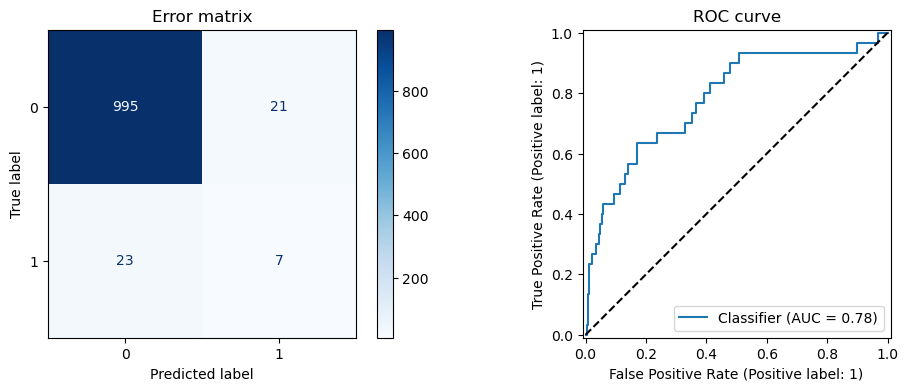

In [673]:
log_reg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
log_reg.fit(X_train, y_train)

evaluate_model(log_reg, X_test, y_test)

` tuned logistic regression `

best params: {'C': 0.1, 'penalty': 'l1', 'solver': 'saga'}
ROC AUC: 0.7919

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1016
           1       0.21      0.20      0.20        30

    accuracy                           0.96      1046
   macro avg       0.59      0.59      0.59      1046
weighted avg       0.95      0.96      0.95      1046



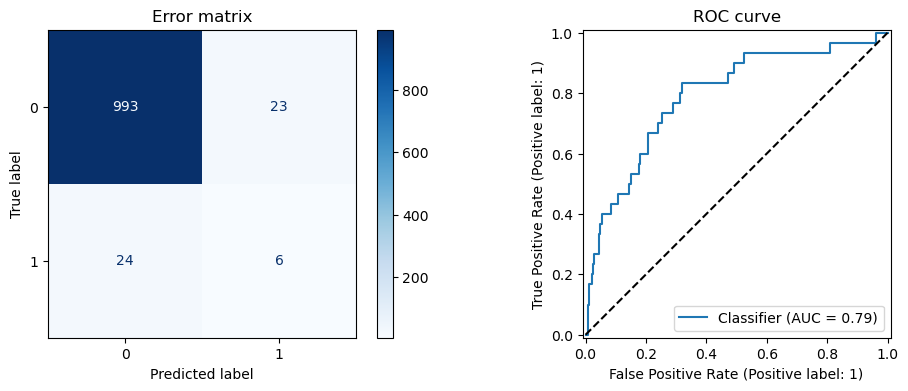

In [ ]:
param_grid = {
    'C': [0.0001, 0.001, 0.01, 0.05, 0.1, 1], 
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga']
}

grid_search = GridSearchCV(
    LogisticRegression(class_weight='balanced', random_state=42, max_iter=2000),
    param_grid,
    scoring='roc_auc',
    cv=5
)

grid_search.fit(X_train, y_train)
extended_tuned_log_reg = grid_search.best_estimator_

print(f"best params: {grid_search.best_params_}")
evaluate_model(extended_tuned_log_reg, X_test, y_test)

1. Класична модель логістичної регресії. Занадто обережна і водночас неуважна. Вона пропускає 77% "1".
Модель намагається провести рівну лінію крізь 256 ознак, але дані про "1", зазвичай, набагато складніші та заплутаніші.

2. Спробуємо покращити модель, додамо підбір параметрів.
Результат не покращився, ROC AUC майже не змінився, це підтверджує, що це практично межа лінійної регресії.

### tree-based models

` decision tree `

ROC AUC: 0.4930

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.95      0.96      1016
           1       0.02      0.03      0.03        30

    accuracy                           0.93      1046
   macro avg       0.50      0.49      0.49      1046
weighted avg       0.94      0.93      0.93      1046



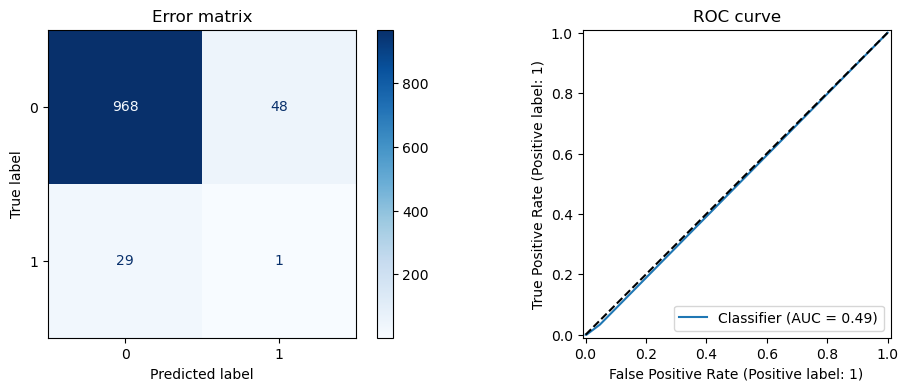

In [682]:
decision_tree = DecisionTreeClassifier(
    max_depth=5, 
    class_weight='balanced', 
    random_state=42
)

decision_tree.fit(X_train, y_train)

evaluate_model(decision_tree, X_test, y_test)

` tuned decision tree `

best params: {'criterion': 'entropy', 'max_depth': 5, 'max_features': None, 'min_samples_leaf': 10, 'min_samples_split': 2}
ROC AUC: 0.4872

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.94      0.96      1016
           1       0.02      0.03      0.02        30

    accuracy                           0.91      1046
   macro avg       0.49      0.49      0.49      1046
weighted avg       0.94      0.91      0.93      1046



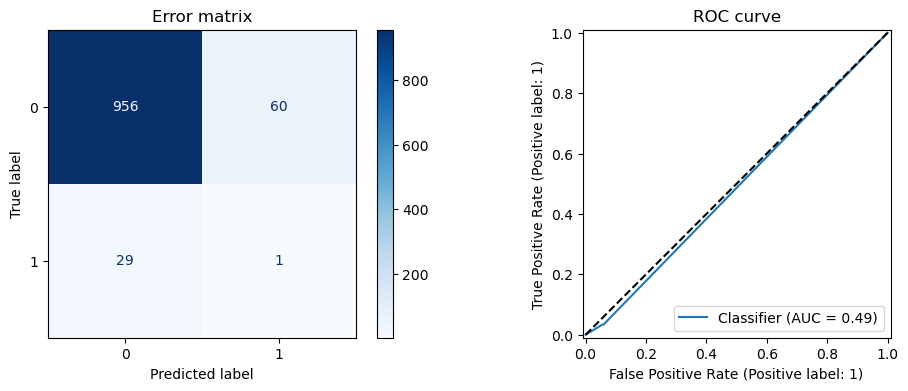

In [684]:
param_grid = {
    'max_depth': [3, 5, 8, 12, 20],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 5, 10, 20],
    'max_features': [None, 'sqrt', 'log2'],
    'criterion': ['gini', 'entropy']
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param_grid,
    scoring='roc_auc',
    cv=5
)

grid_search.fit(X_train, y_train)
tuned_decision_tree = grid_search.best_estimator_

print(f"best params: {grid_search.best_params_}")
evaluate_model(tuned_decision_tree, X_test, y_test)

3. Одиночне дерево не змогло знайти корисних закономірностей, видавши ROC AUC на рівні випадкового вгадування. Пропускає майже всі "1". На це може впливаим висока чутливість дерева до шуму, створюємо помилкові правила, що не працюють на нових даних.

4. Спроюуємо додати підбір оптимальний параметрів. Результат, знову ж таки, не покращився. Підтверджуємо нашу теорію про те, що одного дерева замало для такої моделі. Ми не розпізнаємо клас "1".

` random forest `

ROC AUC: 0.8260

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      1016
           1       1.00      0.03      0.06        30

    accuracy                           0.97      1046
   macro avg       0.99      0.52      0.53      1046
weighted avg       0.97      0.97      0.96      1046



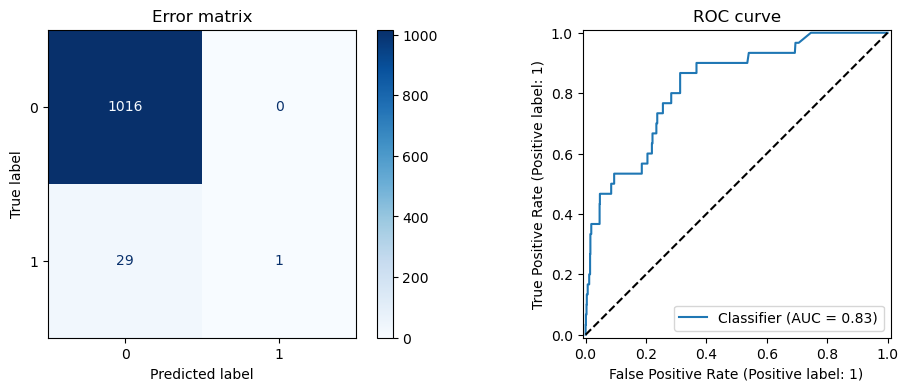

In [686]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)
evaluate_model(random_forest, X_test, y_test)

` tuned random forest `

best params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 300}
ROC AUC: 0.8102

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      1016
           1       1.00      0.03      0.06        30

    accuracy                           0.97      1046
   macro avg       0.99      0.52      0.53      1046
weighted avg       0.97      0.97      0.96      1046



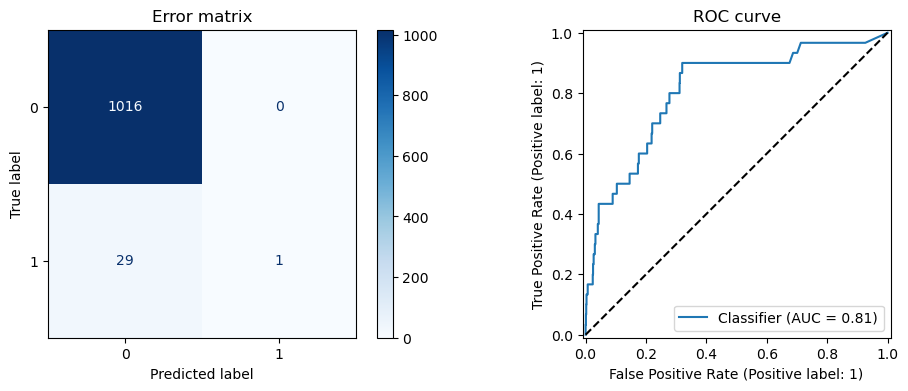

In [688]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

grid_search = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_grid,
    scoring='roc_auc',
    cv=5
)

grid_search.fit(X_train, y_train)
extended_tuned_rf = grid_search.best_estimator_

print(f"best params: {grid_search.best_params_}")
evaluate_model(extended_tuned_rf, X_test, y_test)

` random forest with custom threshold `

best threshold by f1-score: 0.0887

classification report with best threshold:
              precision    recall  f1-score   support

           0       0.98      0.96      0.97      1016
           1       0.23      0.43      0.30        30

    accuracy                           0.94      1046
   macro avg       0.61      0.70      0.63      1046
weighted avg       0.96      0.94      0.95      1046



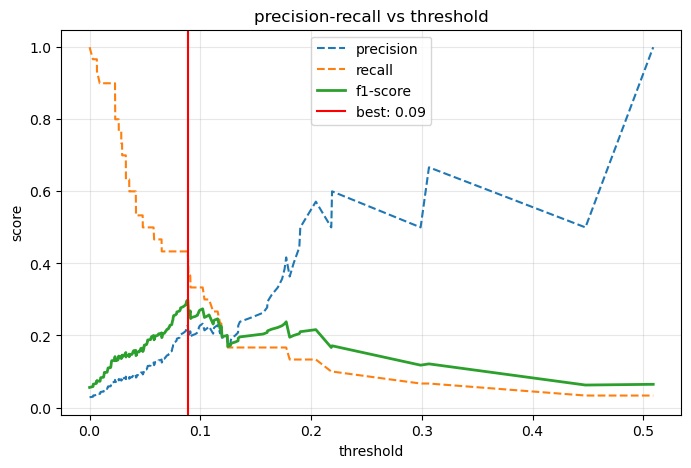

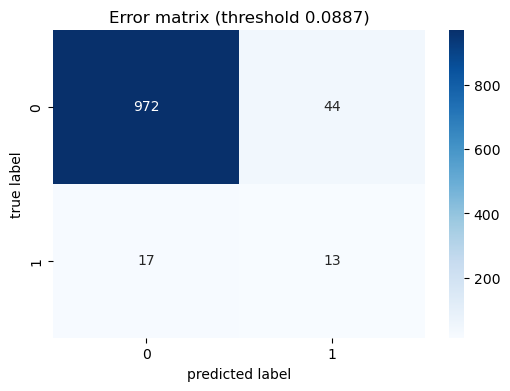

In [717]:
y_scores = extended_tuned_rf.predict_proba(X_test)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_test, y_scores)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"best threshold by f1-score: {best_threshold:.4f}")

y_best_pred = (y_scores >= best_threshold).astype(int)

print("\nclassification report with best threshold:")
print(classification_report(y_test, y_best_pred))

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], label='precision', linestyle='--')
plt.plot(thresholds, recalls[:-1], label='recall', linestyle='--')
plt.plot(thresholds, f1_scores[:-1], label='f1-score', linewidth=2)
plt.axvline(best_threshold, color='red', label=f'best: {best_threshold:.2f}')
plt.title('precision-recall vs threshold')
plt.xlabel('threshold')
plt.ylabel('score')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

y_best_pred = (y_scores >= best_threshold).astype(int)
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_best_pred), annot=True, fmt='d', cmap='Blues')
plt.title(f'Error matrix (threshold {best_threshold:.4f})')
plt.xlabel('predicted label')
plt.ylabel('true label')
plt.show()

5. Random forest одразу працює краще. Чітко розрізняємо клас "0", якщо це дійсно "0".
ROC AUC 0.826 - найкращий показник, кращий за найточнішу класичну логістичну регресію.
Набір дерев набагато краще розуміє структуру даних, ніж поодиноке дерево.

6. Підбір параметрів для попередньої моделі суттєво не змінив ситуацію. Але допоміг нам однозначно визначити, що модель стала надто обережною (Precision = 1 для класу "1"), але ми все ще знаходимо лише одну "1" із 30.
Модель бачить чіткий сигнал для одного випадку, але для інших 29 вона не впевнена настільки, щоб перетнути поріг 0.5.

7. Спробуємо посунути межу вибору класів, щоб модель легше приймала рішення обрати клас "1". Реалізуємо це через обчислення F1-score для кожного можливого порогу класифікації, обираємо оптимальний.
Отримуємо найкращий результат, зниження порогу дозволило піднявти кількість виявлених "1" з 1 до 13 при збереженні високого рівня класифікації "0".

` xgboost `

/opt/anaconda3/lib/python3.13/site-packages/xgboost/core.py:158: UserWarning: [21:30:03] WARNING: /var/folders/k1/30mswbxs7r1g6zwn8y4fyt500000gp/T/abs_d9k8pmaj4_/croot/xgboost-split_1724073758172/work/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


ROC AUC: 0.7595

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1016
           1       0.17      0.03      0.06        30

    accuracy                           0.97      1046
   macro avg       0.57      0.51      0.52      1046
weighted avg       0.95      0.97      0.96      1046



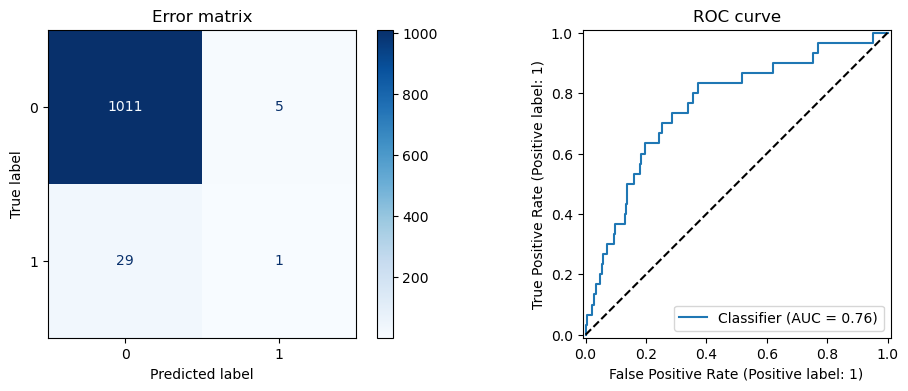

In [697]:
ratio = len(y_train[y_train == 0]) / len(y_train[y_train == 1])

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=ratio,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)
evaluate_model(xgb_model, X_test, y_test)

` tuned xgboost `

ROC AUC: 0.8333

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      1016
           1       0.50      0.07      0.12        30

    accuracy                           0.97      1046
   macro avg       0.74      0.53      0.55      1046
weighted avg       0.96      0.97      0.96      1046



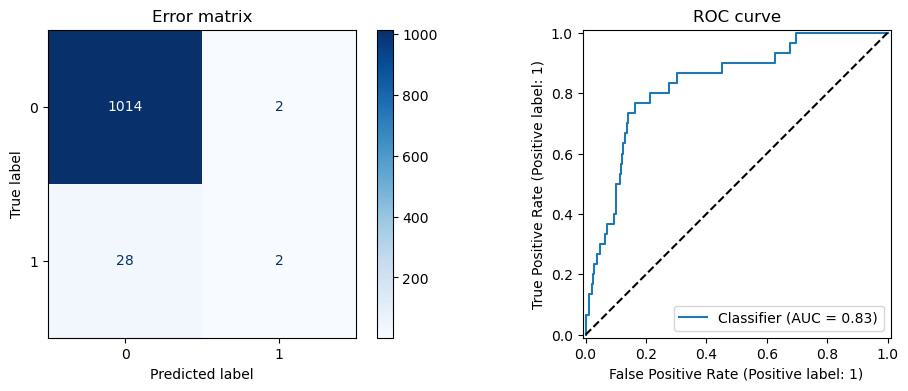

In [705]:
depths = [3, 5, 7]
learning_rates = [0.01, 0.05, 0.1]
reg_alphas = [0, 1, 10]

best_auc = 0
tuned_xgb = None

for d in depths:
    for lr in learning_rates:
        for alpha in reg_alphas:
            model = XGBClassifier(
                n_estimators=200,
                max_depth=d,
                learning_rate=lr,
                reg_alpha=alpha,
                scale_pos_weight=ratio,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                eval_metric='logloss'
            )
            
            model.fit(X_train, y_train)
            probs = model.predict_proba(X_test)[:, 1]
            auc = roc_auc_score(y_test, probs)
            
            if auc > best_auc:
                best_auc = auc
                tuned_xgb = model

evaluate_model(tuned_xgb, X_test, y_test)

` tuned xgboost with custom threshold `

best threshold by f1-score:: 0.0009

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92      1016
           1       0.13      0.73      0.23        30

    accuracy                           0.86      1046
   macro avg       0.56      0.80      0.57      1046
weighted avg       0.97      0.86      0.90      1046



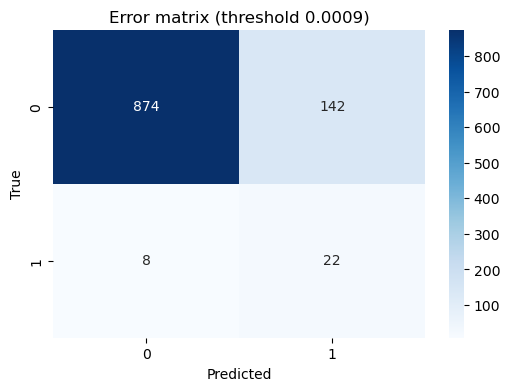

In [722]:
y_scores_xgb = tuned_xgb.predict_proba(X_test)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_test, y_scores_xgb)

f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"best threshold by f1-score:: {best_threshold:.4f}")

y_final_pred = (y_scores_xgb >= best_threshold).astype(int)

print("\nClassification Report:")
print(classification_report(y_test, y_final_pred))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_final_pred), annot=True, fmt='d', cmap='Blues')
plt.title(f'Error matrix (threshold {best_threshold:.4f})')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

8. Майже ідеальна класифікація "0". ROC AUC 0.7595. Модель має хороший потенціал для розділення класів (крива достатньо вище діагоналі), але стандартний поріг 0.5 для неї занадто високий.

9. Попри це, спочатку спробуємо оптимізувати параметри для xgboost. [Стандартна бібліотека не оновлена, не ризикуватимемо вкінці експерименту з оновленнями, тому реалізуємо алгоритм власноруч]. ROC AUC: 0.8333 та покращення виявлення і "0" і "1". Дуже хороший результат, тому, перевіримо, чи зможе ще більше покращити цю ситуацію зміна межі вибору класів.

10. Наш найкращий результат. Проблема з межею вибору класів таки була, і після її зміни ми правильно оприділяємо клас нулів з точністю 0.86, що непогано для більшого класу. Та 0.73 для класу "1", вважатимемо це дуже хорошим результатом, порівняно з початковими спробами, де ми практично не могли знайти "1". 
Такий показник підтверджує, що модель не вгадує, а насправді, добре розрізняє патерни поведінки двох різних класів.

### model ensembles

Для моделі на свій розсуд обрав ансамблі на основі голосування.

Оскільки кожна наша модельЮ попри те, що була кращою чи гіршою, помилялася по-своєму.
Voting classifier може спробувати нівелювати ці індивідуальні вразливості, та видати більш збалансований і стабільний прогноз.

` voting classifier `

Optimal Ensemble Threshold: 0.2514

Ensemble Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1016
           1       0.37      0.23      0.29        30

    accuracy                           0.97      1046
   macro avg       0.67      0.61      0.63      1046
weighted avg       0.96      0.97      0.96      1046



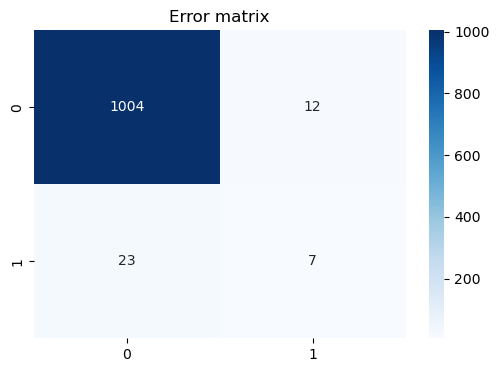

In [726]:
probs_lr = log_reg.predict_proba(X_test)[:, 1]
probs_rf = extended_tuned_rf.predict_proba(X_test)[:, 1]
probs_xgb = tuned_xgb.predict_proba(X_test)[:, 1]


probs_ensemble = (probs_lr + probs_rf + probs_xgb) / 3

precisions, recalls, thresholds = precision_recall_curve(y_test, probs_ensemble)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold_ensemble = thresholds[np.argmax(f1_scores)]

print(f"Optimal Ensemble Threshold: {best_threshold_ensemble:.4f}")

y_ensemble_pred = (probs_ensemble >= best_threshold_ensemble).astype(int)

print("\nEnsemble Classification Report:")
print(classification_report(y_test, y_ensemble_pred))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_ensemble_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Error matrix')
plt.show()

` weighted voting classifier `

Optimal Weighted Threshold: 0.1308

Weighted Ensemble Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.98      1016
           1       0.26      0.30      0.28        30

    accuracy                           0.96      1046
   macro avg       0.62      0.64      0.63      1046
weighted avg       0.96      0.96      0.96      1046



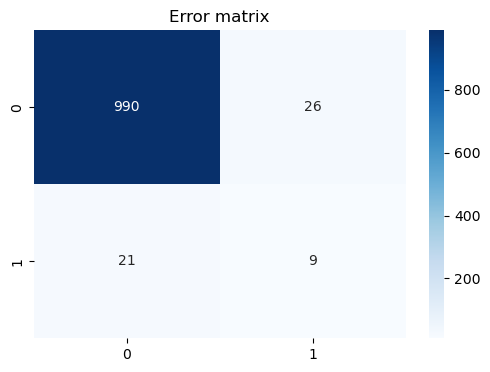

In [727]:
w_lr = 0.2
w_rf = 0.3
w_xgb = 0.5

weighted_probs = (probs_lr * w_lr) + (probs_rf * w_rf) + (probs_xgb * w_xgb)

precisions, recalls, thresholds = precision_recall_curve(y_test, weighted_probs)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold_weighted = thresholds[np.argmax(f1_scores)]

print(f"Optimal Weighted Threshold: {best_threshold_weighted:.4f}")

y_weighted_pred = (weighted_probs >= best_threshold_weighted).astype(int)

print("\nWeighted Ensemble Classification Report:")
print(classification_report(y_test, y_weighted_pred))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_weighted_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Error matrix')
plt.show()

` radical recall `

Manual Threshold: 0.05
              precision    recall  f1-score   support

           0       0.98      0.94      0.96      1016
           1       0.16      0.37      0.22        30

    accuracy                           0.93      1046
   macro avg       0.57      0.66      0.59      1046
weighted avg       0.96      0.93      0.94      1046



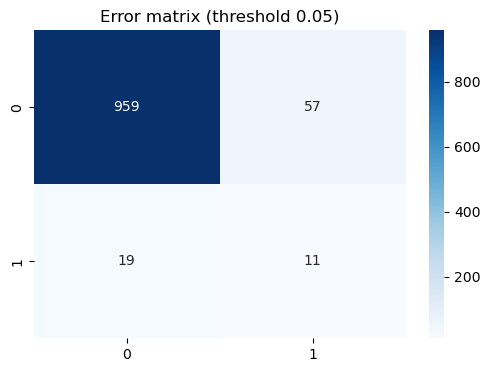

In [728]:
w_lr, w_rf, w_xgb = 0.1, 0.4, 0.5
final_probs = (probs_lr * w_lr) + (probs_rf * w_rf) + (probs_xgb * w_xgb)

manual_threshold = 0.05 

y_manual_pred = (final_probs >= manual_threshold).astype(int)

print(f"Manual Threshold: {manual_threshold}")
print(classification_report(y_test, y_manual_pred))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_manual_pred), annot=True, fmt='d', cmap='Blues')
plt.title(f'Error matrix (threshold {manual_threshold})')
plt.show()

11. Ансамбль показав непоганий результат. Він вгадав менше "1", ніж окремий XGBoost, precision - 0.37 значно вищий.
Допоміг уникнути великої кількості помилкових тривог, які ми бачили в XGBoost, лише 12 хибних спрацювань замість 142.

12. Зважений ансамбль спрацював краще з виявлнням "1", але почав трохи більше помилятися в класі "0".

13. Та, звичайно, спроюуємо модель із зміною межі вибору класів. Дуже хороший результат, 0.94 визначених "0" та 0.37 визначених "1". Результат також дуже хороштий, та показники точності на високому рівні.



### Conclusion

Найкращим алгоритмом обираємо ` tuned xgboost with custom threshold `.

Попри неідеальне визначення класу "0", ми досягли найкращого результату в "1" - 22 з 30 визначених об'єктів меншого з двох дуже дисбалансних класів.
Припускаю, що визначення класу "1" для нас важливіше, оскільки це про якусь виняткову ситуацію.

До того ж, 0.86 для "0" - це також дуже хороший результат. Можель помиляється, але не досить рідко, та ці випадки можна опрацювати вручну чи якось додатково перевірити.

Вкінці запустимо тренування на найкращій моделі для повного набору даних, без розділення на train та test, щоб отримати найкращу модель класифікації.
Її точність ми не зможемо визначити, але, наприклад, маючи новий набір таких даних без цільової змінної з потребою її визначення, з допомогою ` prepare_raw_data ` зможемо  спрогнозувати "gb" для такого набору даних.

In [735]:
X_full = pd.concat([X_train, X_test])
y_full = pd.concat([y_train, y_test])

In [739]:
tuned_xgb.fit(X_full, y_full);

# Feature Importance

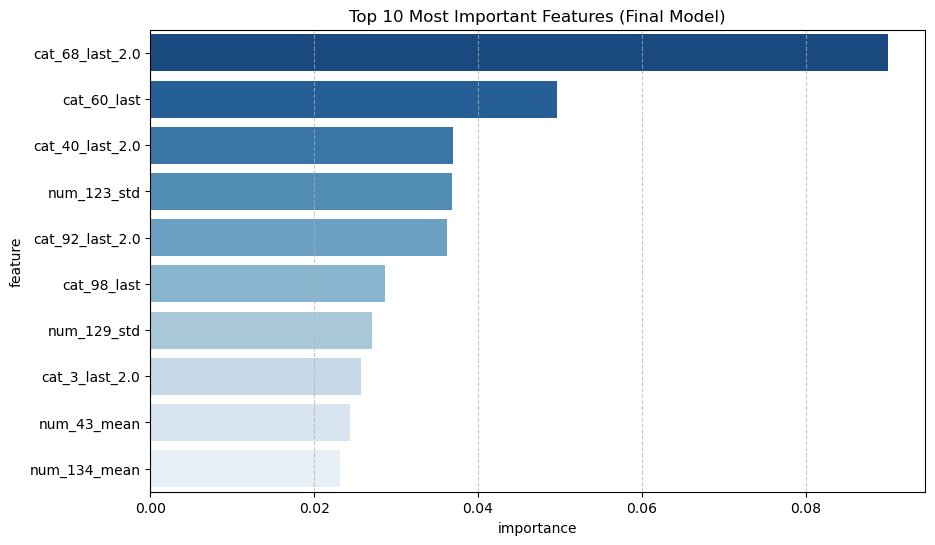

In [742]:
importances = tuned_xgb.feature_importances_
feature_importance_df = pd.DataFrame({
    'feature': X_full.columns,
    'importance': importances
}).sort_values(by='importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='importance', 
    y='feature', 
    data=feature_importance_df.head(10), 
    palette='Blues_r',
    hue='feature',
    legend=False
)
plt.title('Top 10 Most Important Features (Final Model)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()